# Práctica 0 - Entropía de Imágenes

## Objetivo de la práctica
Este cuaderno lee `images_pr0.zip`, calcula entropía en gris y color, genera histogramas y boxplots por categoría, aplica modificaciones en 10 imágenes y crea automáticamente un informe en **HTML** y **PDF**.

Para que sea liviano en clase, se usa un máximo de **20 imágenes por categoría**.

## Teoría (resumen claro)
La entropía de Shannon mide la cantidad de información o incertidumbre:

$$
H = -\sum_i p_i\log_2(p_i)
$$

En imágenes:
- Entropía baja: imagen más uniforme (menos variación de píxeles).
- Entropía alta: imagen con más detalle, textura, ruido o cambios de color.

En gris se analiza la variación de intensidades.
En color (RGB) se analiza la variación conjunta de los canales.

## Qué debe mostrar el informe
- Imagen, nombre/ruta e histogramas en gris y color.
- Entropía por imagen (gris y RGB).
- Boxplots por categoría.
- Análisis de categorías con mayor entropía.
- Cambios de entropía tras modificaciones pequeña, mediana y grande.

In [2]:
# 1) Instalación rápida (si hace falta)
# Descomenta si no tienes skimage:
# %pip install scikit-image

# 2) Importaciones y configuración
from pathlib import Path
import random
import zipfile
import base64
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from skimage import util
from skimage.measure import shannon_entropy

sns.set_theme(style='whitegrid')

BASE_DIR = Path('.').resolve()
ZIP_PATH = BASE_DIR / 'images_pr0.zip'
DATA_DIR = BASE_DIR / 'data' / 'images_extracted'
OUT_DIR = BASE_DIR / 'output'
PLOTS_DIR = OUT_DIR / 'plots'
HIST_DIR = PLOTS_DIR / 'histograms'
SAMPLES_DIR = OUT_DIR / 'samples'

for p in [DATA_DIR, OUT_DIR, PLOTS_DIR, HIST_DIR, SAMPLES_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print('ZIP existe:', ZIP_PATH.exists())
print('Salida:', OUT_DIR)

ZIP existe: True
Salida: /home/michi/Documents/Vision del computador/Practica 0/output


In [3]:
# 3) Leer ZIP y limitar a max 20 imágenes por clase
VALID_EXTS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff', '.webp'}
MAX_PER_CLASS = 20

if not ZIP_PATH.exists():
    raise FileNotFoundError(f'No existe: {ZIP_PATH}')

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(DATA_DIR)

all_images = [p for p in DATA_DIR.rglob('*') if p.is_file() and p.suffix.lower() in VALID_EXTS]
all_images = sorted(all_images)

# Detectar clase real (ejemplo: training_set/beaches/xxx.jpg -> clase=beaches)
rows = []
for p in all_images:
    rel = p.relative_to(DATA_DIR)
    parts = rel.parts

    split = parts[0] if len(parts) > 0 else 'sin_split'
    if len(parts) >= 3 and parts[0] in {'training_set', 'test_set', 'validation_set'}:
        category = parts[1]
    elif len(parts) >= 2:
        category = parts[0]
    else:
        category = 'sin_categoria'

    rows.append({'path': p, 'split': split, 'category': category})

img_df = pd.DataFrame(rows)

# Limitar a 20 por clase
img_df = img_df.groupby('category', group_keys=False).head(MAX_PER_CLASS).reset_index(drop=True)
image_paths = img_df['path'].tolist()
path_to_category = dict(zip(img_df['path'], img_df['category']))

print('Total imágenes usadas:', len(image_paths))
print('Imágenes por clase:')
display(img_df['category'].value_counts().to_frame('cantidad'))

Total imágenes usadas: 200
Imágenes por clase:


,cantidad
category,
beaches,20
bus,20
dinosaurs,20
elephants,20
flowers,20
foods,20
horses,20
monuments,20
mountains_and_snow,20


In [4]:
# 4) Entropía por imagen + histogramas (gris y color)
records = []

for i, path in enumerate(image_paths, start=1):
    rgb = np.array(Image.open(path).convert('RGB'))
    gray = (0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]).astype(np.uint8)

    e_gray = float(shannon_entropy(gray))
    e_rgb = float(shannon_entropy(rgb))

    # Guardar histogramas
    stem = path.stem.replace(' ', '_')
    h_gray = HIST_DIR / f'{stem}_hist_gray.png'
    h_rgb = HIST_DIR / f'{stem}_hist_rgb.png'

    plt.figure(figsize=(5, 3.5))
    plt.hist(gray.ravel(), bins=256, range=(0, 255), color='gray')
    plt.title(f'Histograma gris: {path.name}')
    plt.xlabel('Intensidad')
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.savefig(h_gray, dpi=110)
    plt.close()

    plt.figure(figsize=(5, 3.5))
    plt.hist(rgb[..., 0].ravel(), bins=256, alpha=0.4, color='red', label='R')
    plt.hist(rgb[..., 1].ravel(), bins=256, alpha=0.4, color='green', label='G')
    plt.hist(rgb[..., 2].ravel(), bins=256, alpha=0.4, color='blue', label='B')
    plt.title(f'Histograma color: {path.name}')
    plt.xlabel('Intensidad')
    plt.ylabel('Frecuencia')
    plt.legend()
    plt.tight_layout()
    plt.savefig(h_rgb, dpi=110)
    plt.close()

    records.append({
        'image_name': path.name,
        'image_path': str(path.relative_to(BASE_DIR)),
        'category': path_to_category.get(path, 'sin_categoria'),
        'entropy_gray': e_gray,
        'entropy_rgb': e_rgb,
        'hist_gray_path': str(h_gray.relative_to(BASE_DIR)),
        'hist_rgb_path': str(h_rgb.relative_to(BASE_DIR)),
    })

entropy_df = pd.DataFrame(records)
print('Imágenes procesadas:', len(entropy_df))
entropy_df.head()

Imágenes procesadas: 200


,image_name,image_path,category,entropy_gray,entropy_rgb,hist_gray_path,hist_rgb_path
0,110.jpg,data/images_extracted/training_set/beaches/110...,beaches,7.331672,7.463872,output/plots/histograms/110_hist_gray.png,output/plots/histograms/110_hist_rgb.png
1,111.jpg,data/images_extracted/training_set/beaches/111...,beaches,7.294844,7.654925,output/plots/histograms/111_hist_gray.png,output/plots/histograms/111_hist_rgb.png
2,112.jpg,data/images_extracted/training_set/beaches/112...,beaches,7.424493,7.702022,output/plots/histograms/112_hist_gray.png,output/plots/histograms/112_hist_rgb.png
3,113.jpg,data/images_extracted/training_set/beaches/113...,beaches,7.445432,7.557798,output/plots/histograms/113_hist_gray.png,output/plots/histograms/113_hist_rgb.png
4,114.jpg,data/images_extracted/training_set/beaches/114...,beaches,7.567491,7.618800,output/plots/histograms/114_hist_gray.png,output/plots/histograms/114_hist_rgb.png


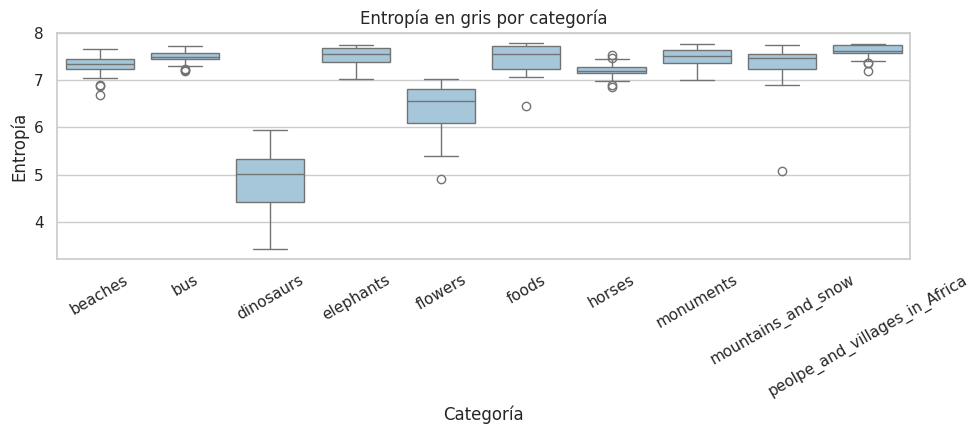

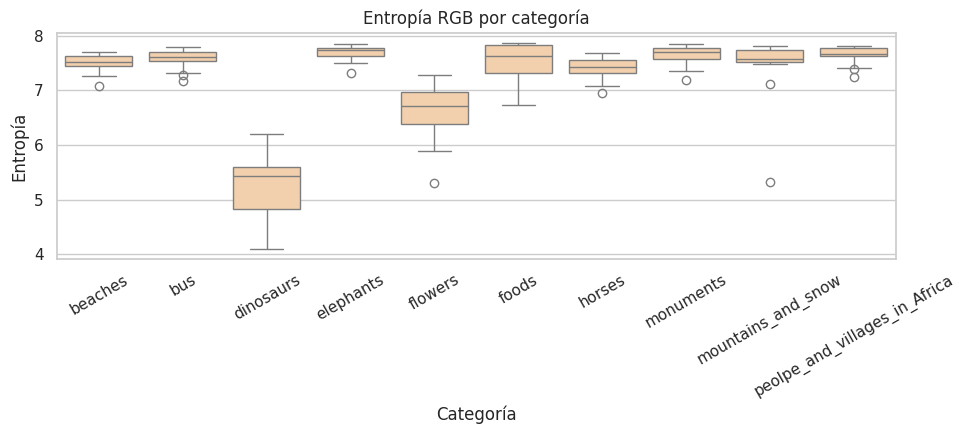

Guardado: output/plots/boxplot_entropy_gray_by_category.png
Guardado: output/plots/boxplot_entropy_rgb_by_category.png


,category,entropy_gray,entropy_rgb
3,elephants,7.507508,7.690988
9,peolpe_and_villages_in_Africa,7.599699,7.649622
7,monuments,7.466447,7.645826
1,bus,7.479503,7.578944
5,foods,7.453801,7.561110
0,beaches,7.295542,7.511141
8,mountains_and_snow,7.290276,7.493477
6,horses,7.205181,7.404251
4,flowers,6.371451,6.609605
2,dinosaurs,4.854319,5.219270


Mayor entropía RGB media: elephants (7.691)
Esto suele pasar cuando hay más variedad de colores, texturas o ruido en esa clase.


In [5]:
# 5) Boxplots por categoría (X=categoría, Y=entropía)
box_gray = PLOTS_DIR / 'boxplot_entropy_gray_by_category.png'
box_rgb = PLOTS_DIR / 'boxplot_entropy_rgb_by_category.png'

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=entropy_df, x='category', y='entropy_gray', color='#9ecae1')
plt.title('Entropía en gris por categoría')
plt.xlabel('Categoría')
plt.ylabel('Entropía')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(box_gray, dpi=120)
plt.show()

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=entropy_df, x='category', y='entropy_rgb', color='#fdd0a2')
plt.title('Entropía RGB por categoría')
plt.xlabel('Categoría')
plt.ylabel('Entropía')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(box_rgb, dpi=120)
plt.show()

print('Guardado:', box_gray.relative_to(BASE_DIR))
print('Guardado:', box_rgb.relative_to(BASE_DIR))

# Análisis simple: categoría con mayor entropía media
cat_mean = entropy_df.groupby('category', as_index=False)[['entropy_gray', 'entropy_rgb']].mean()
display(cat_mean.sort_values('entropy_rgb', ascending=False))

top_cat = cat_mean.sort_values('entropy_rgb', ascending=False).iloc[0]
print(f"Mayor entropía RGB media: {top_cat['category']} ({top_cat['entropy_rgb']:.3f})")
print('Esto suele pasar cuando hay más variedad de colores, texturas o ruido en esa clase.')

## Ejemplos visuales

Las siguientes imágenes sirven como muestra del conjunto de datos. Para cada una se muestra la imagen original y sus histogramas en escala de grises y en color.

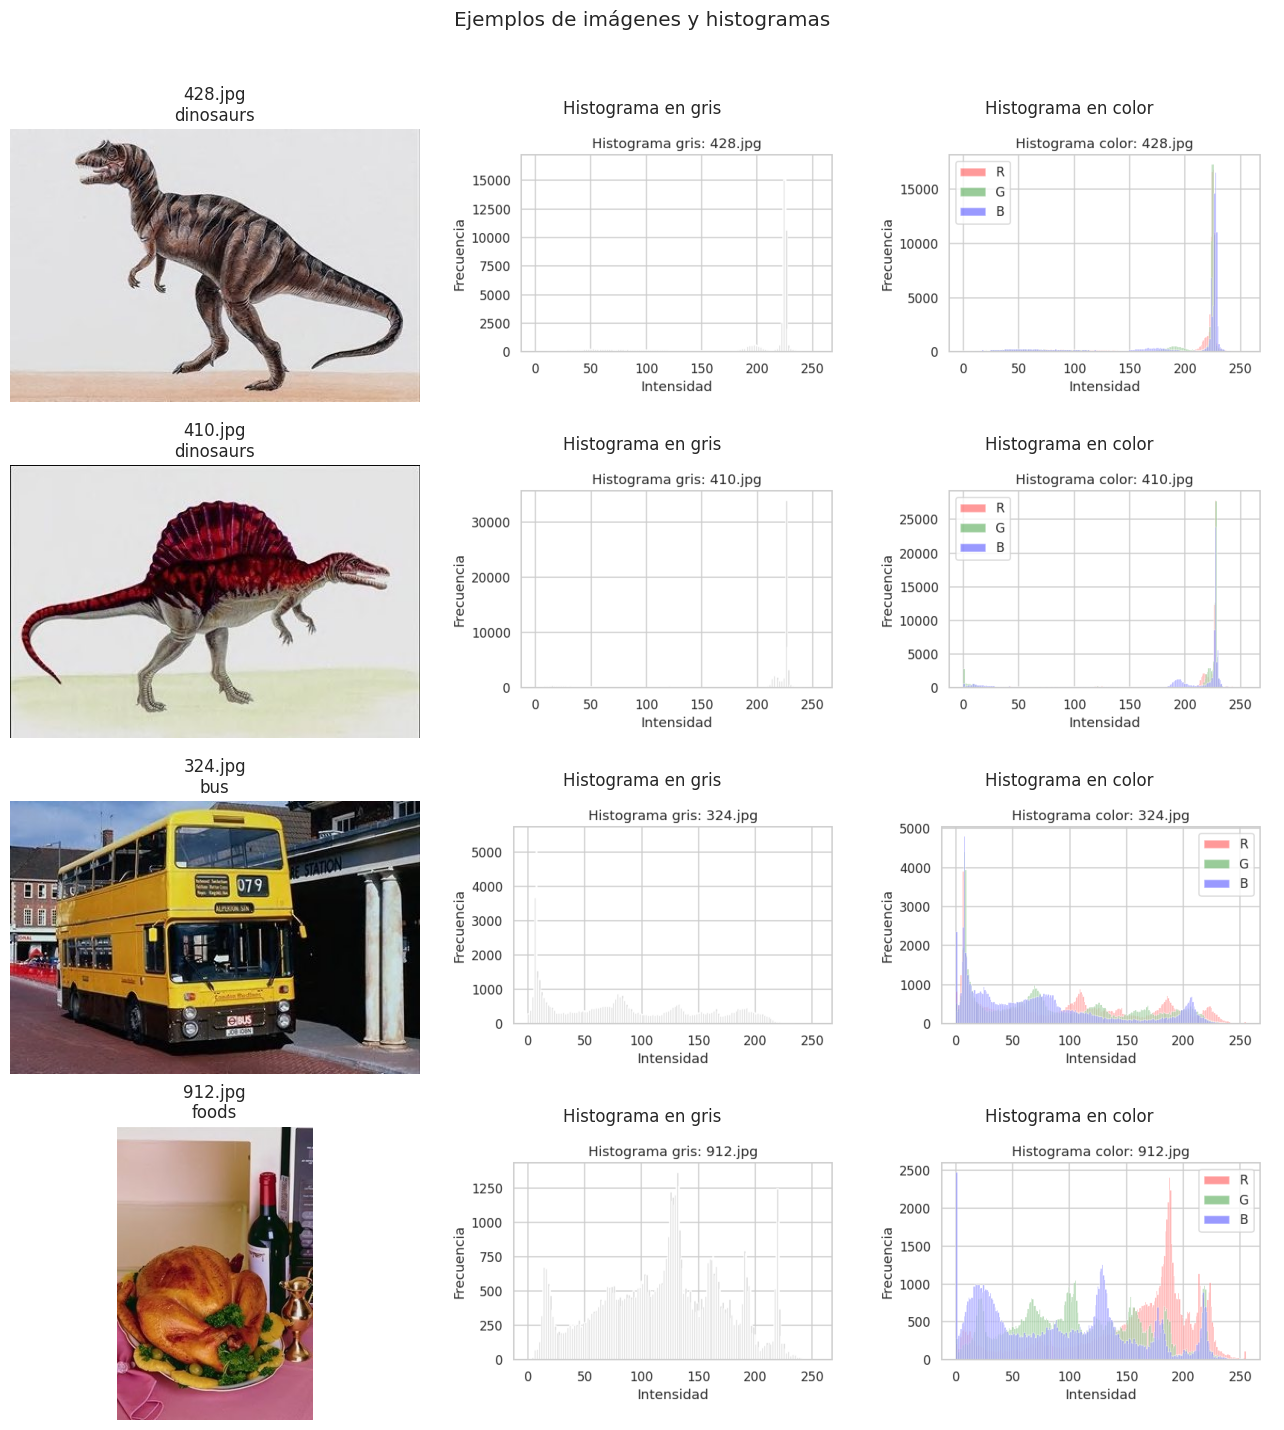

In [9]:
# Mostrar algunos ejemplos del dataset con sus histogramas
sample_examples = entropy_df.sample(n=min(4, len(entropy_df)), random_state=1).reset_index(drop=True)

fig, axes = plt.subplots(len(sample_examples), 3, figsize=(13, 3.5 * len(sample_examples)))
if len(sample_examples) == 1:
    axes = np.array([axes])

for i, row in sample_examples.iterrows():
    img = np.array(Image.open(BASE_DIR / row['image_path']).convert('RGB'))
    gray_hist = plt.imread(BASE_DIR / row['hist_gray_path'])
    rgb_hist = plt.imread(BASE_DIR / row['hist_rgb_path'])

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{row['image_name']}\n{row['category']}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(gray_hist)
    axes[i, 1].set_title('Histograma en gris')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(rgb_hist)
    axes[i, 2].set_title('Histograma en color')
    axes[i, 2].axis('off')

plt.suptitle('Ejemplos de imágenes y histogramas', y=1.02)
plt.tight_layout()
plt.show()

In [6]:
# 6) Modificaciones en 10 imágenes: pequeña, mediana y grande
random.seed(42)
rng = np.random.default_rng(42)

levels = {
    'pequena': {'frac': 0.08, 'sigma': 5},
    'mediana': {'frac': 0.16, 'sigma': 12},
    'grande': {'frac': 0.28, 'sigma': 20},
}

selected = random.sample(image_paths, k=min(10, len(image_paths)))
exp_rows = []

for path in selected:
    img = np.array(Image.open(path).convert('RGB'))
    base_entropy = float(shannon_entropy(img))
    h, w, _ = img.shape

    for level, pars in levels.items():
        mod = img.copy()

        # Clonar un parche pequeño/mediano/grande
        ph, pw = max(8, int(h * pars['frac'])), max(8, int(w * pars['frac']))
        y1 = int(rng.integers(0, max(1, h - ph)))
        x1 = int(rng.integers(0, max(1, w - pw)))
        y2 = int(rng.integers(0, max(1, h - ph)))
        x2 = int(rng.integers(0, max(1, w - pw)))
        mod[y2:y2 + ph, x2:x2 + pw] = mod[y1:y1 + ph, x1:x1 + pw]

        # Añadir un poco de ruido
        noisy = util.random_noise(mod, mode='gaussian', var=(pars['sigma'] / 255.0) ** 2)
        mod = (np.clip(noisy, 0, 1) * 255).astype(np.uint8)

        after_entropy = float(shannon_entropy(mod))

        out_img = SAMPLES_DIR / f'{path.stem}_{level}.png'
        Image.fromarray(mod).save(out_img)

        exp_rows.append({
            'image_name': path.name,
            'category': path_to_category.get(path, 'sin_categoria'),
            'level': level,
            'entropy_before': base_entropy,
            'entropy_after': after_entropy,
            'delta_entropy': after_entropy - base_entropy,
            'modified_path': str(out_img.relative_to(BASE_DIR)),
        })

exp_df = pd.DataFrame(exp_rows)
exp_df.head()

,image_name,category,level,entropy_before,entropy_after,delta_entropy,modified_path
0,813.jpg,mountains_and_snow,pequena,7.52816,7.561709,0.033549,output/samples/813_pequena.png
1,813.jpg,mountains_and_snow,mediana,7.52816,7.619467,0.091307,output/samples/813_mediana.png
2,813.jpg,mountains_and_snow,grande,7.52816,7.745554,0.217394,output/samples/813_grande.png
3,318.jpg,bus,pequena,7.55259,7.544775,-0.007814,output/samples/318_pequena.png
4,318.jpg,bus,mediana,7.55259,7.545832,-0.006758,output/samples/318_mediana.png


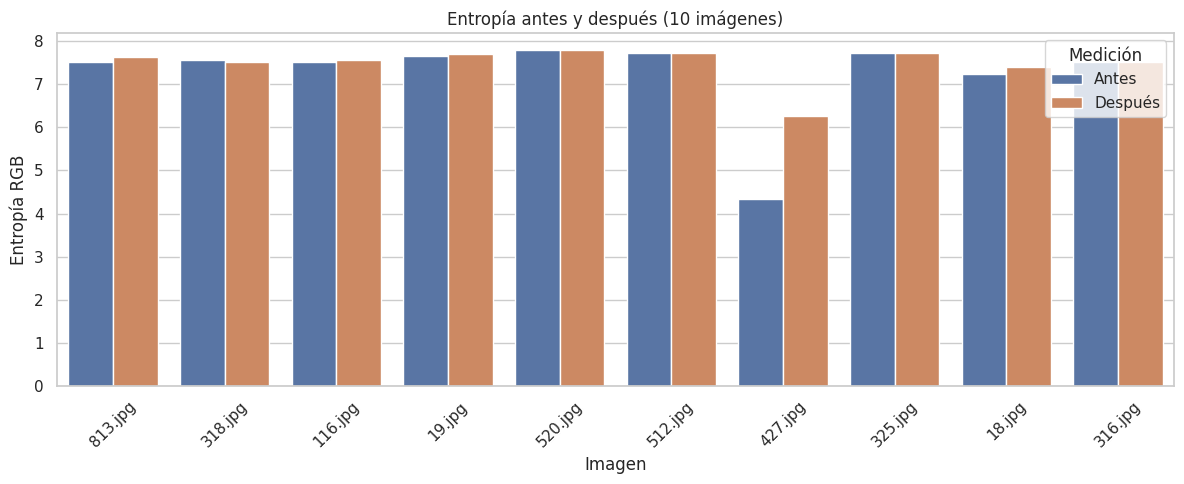

Resumen por nivel:


,level,entropy_before,entropy_after,delta_entropy
0,grande,7.26187,7.515401,0.253531
1,mediana,7.26187,7.514117,0.252247
2,pequena,7.26187,7.426750,0.164880


Guardado: output/plots/experimental_entropy_comparison.png


In [7]:
# 7) Barras comparativas antes vs después
bar_path = PLOTS_DIR / 'experimental_entropy_comparison.png'

plot_df = exp_df.melt(
    id_vars=['image_name', 'level'],
    value_vars=['entropy_before', 'entropy_after'],
    var_name='type',
    value_name='entropy'
)

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='image_name', y='entropy', hue='type', errorbar=None)
plt.title('Entropía antes y después (10 imágenes)')
plt.xlabel('Imagen')
plt.ylabel('Entropía RGB')
plt.xticks(rotation=45)
plt.legend(title='Medición', labels=['Antes', 'Después'])
plt.tight_layout()
plt.savefig(bar_path, dpi=120)
plt.show()

level_summary = exp_df.groupby('level', as_index=False)[['entropy_before', 'entropy_after', 'delta_entropy']].mean()
print('Resumen por nivel:')
display(level_summary)
print('Guardado:', bar_path.relative_to(BASE_DIR))

## Comparación de modificaciones

En este bloque se compara una imagen original con sus tres versiones modificadas. La idea es observar cómo cambia la apariencia visual y cómo se refleja en la entropía.

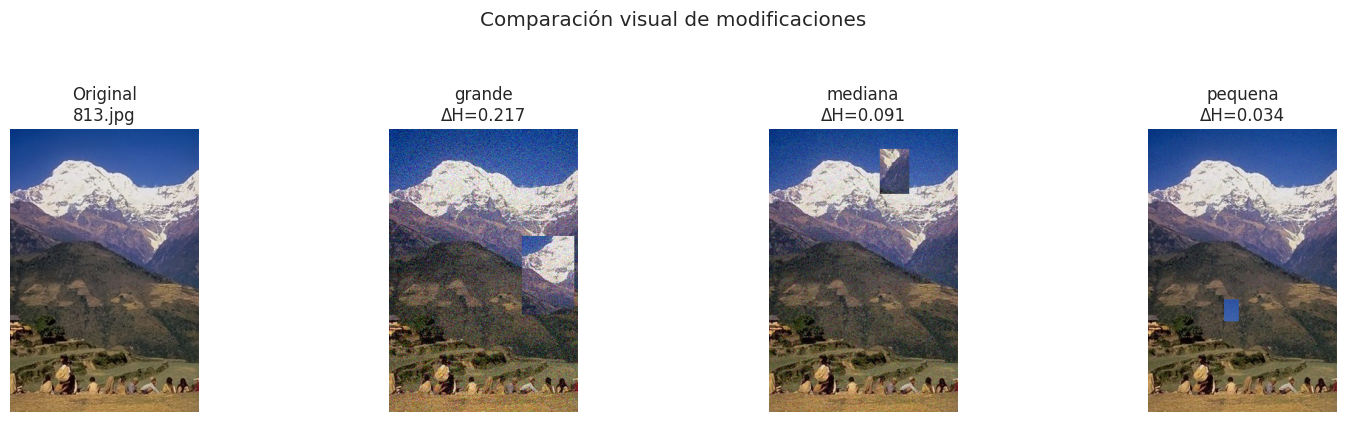

Imagen comparada: 813.jpg


,level,entropy_before,entropy_after,delta_entropy
2,grande,7.52816,7.745554,0.217394
1,mediana,7.52816,7.619467,0.091307
0,pequena,7.52816,7.561709,0.033549


In [8]:
# Comparación de una imagen original con sus tres modificaciones
sample_name = exp_df['image_name'].iloc[0]
orig_row = entropy_df[entropy_df['image_name'] == sample_name].iloc[0]
mods = exp_df[exp_df['image_name'] == sample_name].sort_values('level')

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

original_img = np.array(Image.open(BASE_DIR / orig_row['image_path']).convert('RGB'))
axes[0].imshow(original_img)
axes[0].set_title(f"Original\n{sample_name}")
axes[0].axis('off')

for ax, (_, row) in zip(axes[1:], mods.iterrows()):
    mod_img = np.array(Image.open(BASE_DIR / row['modified_path']).convert('RGB'))
    ax.imshow(mod_img)
    ax.set_title(f"{row['level']}\nΔH={row['delta_entropy']:.3f}")
    ax.axis('off')

plt.suptitle('Comparación visual de modificaciones', y=1.05)
plt.tight_layout()
plt.show()

print(f"Imagen comparada: {sample_name}")
display(mods[['level', 'entropy_before', 'entropy_after', 'delta_entropy']])

## Exportación automática del informe

Al ejecutar el cuaderno completo se genera un resumen en HTML y, si es posible, también en PDF.

In [10]:
# Exportación automática del informe (formato alineado al cuaderno)
report_html = OUT_DIR / 'report_latest.html'
report_pdf = OUT_DIR / 'report_latest.pdf'

def b64(path: Path) -> str:
    return base64.b64encode(path.read_bytes()).decode('utf-8')

# Datos base para el informe
top_cat_row = cat_mean.sort_values('entropy_rgb', ascending=False).iloc[0]
top3 = cat_mean.sort_values('entropy_rgb', ascending=False).head(3)
example_rows = entropy_df.sample(n=min(4, len(entropy_df)), random_state=7).reset_index(drop=True)

# Sección de ejemplos: imagen + ruta + histogramas
cards = []
for _, row in example_rows.iterrows():
    img_path = BASE_DIR / row['image_path']
    hg_path = BASE_DIR / row['hist_gray_path']
    hr_path = BASE_DIR / row['hist_rgb_path']
    cards.append(f"""
    <div class='card'>
      <h3>{row['image_name']}</h3>
      <p><b>Ruta:</b> {row['image_path']}<br><b>Categoría:</b> {row['category']}</p>
      <p><b>Entropía gris:</b> {row['entropy_gray']:.3f} | <b>Entropía RGB:</b> {row['entropy_rgb']:.3f}</p>
      <img src='data:image/png;base64,{b64(img_path)}' class='main'>
      <div class='row'>
        <img src='data:image/png;base64,{b64(hg_path)}' class='small'>
        <img src='data:image/png;base64,{b64(hr_path)}' class='small'>
      </div>
    </div>
    """)

# Sección de comparación de modificaciones para varias imágenes
cmp_names = exp_df['image_name'].drop_duplicates().head(3).tolist()
mod_sections = []

for cmp_name in cmp_names:
    cmp_orig = entropy_df[entropy_df['image_name'] == cmp_name].iloc[0]
    cmp_mods = exp_df[exp_df['image_name'] == cmp_name].sort_values('level')

    section_cards = []
    orig_path = BASE_DIR / cmp_orig['image_path']
    section_cards.append(f"""
    <div class='mini-card'>
      <h4>Original</h4>
      <img src='data:image/png;base64,{b64(orig_path)}' class='mini-img'>
    </div>
    """)

    for _, row in cmp_mods.iterrows():
        mod_path = BASE_DIR / row['modified_path']
        section_cards.append(f"""
        <div class='mini-card'>
          <h4>{row['level']} (ΔH={row['delta_entropy']:.3f})</h4>
          <img src='data:image/png;base64,{b64(mod_path)}' class='mini-img'>
        </div>
        """)

    mod_sections.append(f"""
    <div class='subsection'>
      <h3>Imagen: {cmp_name}</h3>
      <div class='mini-grid'>
        {''.join(section_cards)}
      </div>
    </div>
    """)

html = f"""
<html>
<head>
  <meta charset='utf-8'>
  <title>Práctica 0 - Entropía de imágenes</title>
  <style>
    body {{ font-family: Arial, sans-serif; margin: 0; background: #f6f7fb; color: #1f2937; }}
    .wrap {{ max-width: 1100px; margin: 0 auto; padding: 28px 24px 36px; }}
    .hero {{ background: linear-gradient(135deg, #1f3b73, #284e8b); color: white; border-radius: 16px; padding: 24px 28px; margin-bottom: 20px; }}
    .hero h1 {{ margin: 0 0 8px; font-size: 2rem; }}
    .hero p {{ margin: 0; opacity: 0.95; }}
    .section {{ background: white; border: 1px solid #e5e7eb; border-radius: 14px; padding: 18px; margin: 16px 0; box-shadow: 0 1px 2px rgba(0,0,0,0.04); }}
    .subsection {{ border: 1px solid #e5e7eb; border-radius: 12px; padding: 12px; margin-bottom: 12px; background: #fcfdff; }}
    h2 {{ margin-top: 0; color: #1f3b73; font-size: 1.2rem; }}
    h3 {{ margin: 0 0 8px; color: #1f3b73; font-size: 1rem; }}
    .metrics {{ display: grid; grid-template-columns: repeat(4, minmax(0, 1fr)); gap: 12px; }}
    .metric {{ background: #f9fafb; border: 1px solid #e5e7eb; border-radius: 12px; padding: 12px; }}
    .metric .label {{ color: #6b7280; font-size: 0.9rem; }}
    .metric .value {{ font-size: 1.15rem; font-weight: 700; margin-top: 4px; }}
    .grid {{ display: grid; grid-template-columns: 1fr; gap: 16px; }}
    .card {{ border: 1px solid #e5e7eb; border-radius: 12px; padding: 12px; background: #fff; }}
    .main {{ width: 100%; max-width: 720px; border-radius: 8px; display: block; margin: 10px 0; }}
    .small {{ width: 49%; border-radius: 8px; }}
    .row {{ display: flex; gap: 10px; flex-wrap: wrap; }}
    .mini-grid {{ display: grid; grid-template-columns: repeat(4, minmax(0, 1fr)); gap: 10px; }}
    .mini-card {{ border: 1px solid #dbe2f0; border-radius: 10px; padding: 10px; background: #fbfcff; }}
    .mini-card h4 {{ margin: 0 0 8px; font-size: 0.95rem; color: #1f3b73; }}
    .mini-img {{ width: 100%; border-radius: 8px; }}
    table {{ border-collapse: collapse; width: 100%; margin-top: 10px; background: white; }}
    th, td {{ border: 1px solid #e5e7eb; padding: 7px 8px; text-align: left; vertical-align: top; }}
    th {{ background: #f3f4f6; }}
    .note {{ color: #4b5563; font-size: 0.96rem; line-height: 1.5; }}
  </style>
</head>
<body>
<div class='wrap'>
  <div class='hero'>
    <h1>Práctica 0 - Entropía de Imágenes</h1>
    <p>Informe automático estructurado con el mismo flujo del cuaderno.</p>
  </div>

  <div class='section'>
    <h2>1. Introducción</h2>
    <p class='note'>Este trabajo procesa el conjunto images_pr0.zip y estudia la complejidad visual de las imágenes mediante entropía de Shannon en escala de grises y en color (RGB). Además, se analizan cambios de entropía al aplicar modificaciones locales y ruido.</p>
    <div class='metrics'>
      <div class='metric'><div class='label'>Imágenes analizadas</div><div class='value'>{len(entropy_df)}</div></div>
      <div class='metric'><div class='label'>Categorías</div><div class='value'>{entropy_df['category'].nunique()}</div></div>
      <div class='metric'><div class='label'>Mayor entropía RGB</div><div class='value'>{top_cat_row['category']}</div></div>
      <div class='metric'><div class='label'>Valor RGB medio</div><div class='value'>{top_cat_row['entropy_rgb']:.3f}</div></div>
    </div>
  </div>

  <div class='section'>
    <h2>2. Fundamento teórico (resumen)</h2>
    <p class='note'>La entropía de Shannon mide incertidumbre o cantidad de información. En imágenes, valores altos indican mayor variabilidad de intensidades, colores y texturas; valores bajos indican mayor uniformidad.</p>
  </div>

  <div class='section'>
    <h2>3. Carga y preparación de datos</h2>
    <p class='note'>Se descomprime images_pr0.zip y se selecciona un máximo de 20 imágenes por categoría para mantener tiempos razonables de ejecución en laboratorio.</p>
  </div>

  <div class='section'>
    <h2>4. Entropía por categoría</h2>
    <p class='note'>Eje X: categoría/clase. Eje Y: nivel de entropía.</p>
    <img src='data:image/png;base64,{b64(box_gray)}' class='main'>
    <img src='data:image/png;base64,{b64(box_rgb)}' class='main'>
    <p class='note'>Top 3 categorías con mayor entropía RGB media:</p>
    {top3.to_html(index=False)}
  </div>

  <div class='section'>
    <h2>5. Modificaciones y comparación</h2>
    <p class='note'>Se aplicaron niveles pequena, mediana y grande en 10 imágenes. El gráfico compara la entropía antes y después.</p>
    <img src='data:image/png;base64,{b64(bar_path)}' class='main'>
    {level_summary.to_html(index=False)}
    <p class='note'><b>Evidencia visual de modificaciones (múltiples ejemplos):</b></p>
    {''.join(mod_sections)}
  </div>

  <div class='section'>
    <h2>6. Ejemplos: imagen, ruta e histogramas</h2>
    <div class='grid'>
      {''.join(cards)}
    </div>
  </div>
</div>
</body>
</html>
"""

report_html.write_text(html, encoding='utf-8')
print('HTML generado:', report_html)

try:
    from weasyprint import HTML
    HTML(string=html, base_url=str(BASE_DIR)).write_pdf(str(report_pdf))
    print('PDF generado:', report_pdf)
except Exception:
    from matplotlib.backends.backend_pdf import PdfPages

    with PdfPages(report_pdf) as pdf:
        # Página 1: Introducción y teoría
        fig = plt.figure(figsize=(11, 8.5))
        plt.axis('off')
        text = (
            'Práctica 0 - Entropía de Imágenes\n\n'
            '1) Introducción\n'
            'Se analiza images_pr0.zip con entropía en gris y RGB.\n\n'
            '2) Teoría\n'
            'Entropía alta implica mayor variabilidad visual (textura, color, ruido).\n'
            'Entropía baja implica mayor uniformidad de píxeles.\n\n'
            f'Imágenes analizadas: {len(entropy_df)}\n'
            f'Categorías: {entropy_df["category"].nunique()}\n'
            f'Mayor entropía RGB: {top_cat_row["category"]} ({top_cat_row["entropy_rgb"]:.3f})\n'
        )
        plt.text(0.05, 0.95, text, va='top', fontsize=12)
        pdf.savefig(fig)
        plt.close(fig)

        # Resultados principales
        for image_path, title in [
            (box_gray, '3) Boxplot de entropía en gris'),
            (box_rgb, '3) Boxplot de entropía en color (RGB)'),
            (bar_path, '4) Comparación antes/después de modificaciones'),
        ]:
            fig = plt.figure(figsize=(11, 8.5))
            plt.imshow(plt.imread(image_path))
            plt.title(title)
            plt.axis('off')
            pdf.savefig(fig)
            plt.close(fig)

        # Página de top 3 categorías
        fig = plt.figure(figsize=(11, 8.5))
        plt.axis('off')
        plt.title('5) Top 3 categorías con mayor entropía RGB', fontsize=14, pad=12)
        tbl = plt.table(
            cellText=top3.values,
            colLabels=top3.columns,
            cellLoc='left',
            colLoc='left',
            loc='center'
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(10)
        tbl.scale(1, 1.7)
        pdf.savefig(fig)
        plt.close(fig)

        # Página de resumen por nivel
        fig = plt.figure(figsize=(11, 8.5))
        plt.axis('off')
        plt.title('6) Resumen por nivel de modificación', fontsize=14, pad=12)
        tbl = plt.table(
            cellText=level_summary.values,
            colLabels=level_summary.columns,
            cellLoc='left',
            colLoc='left',
            loc='center'
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(10)
        tbl.scale(1, 1.8)
        pdf.savefig(fig)
        plt.close(fig)

        # Páginas extra: evidencia visual de modificaciones para varias imágenes
        for cmp_name in cmp_names:
            cmp_orig = entropy_df[entropy_df['image_name'] == cmp_name].iloc[0]
            cmp_mods = exp_df[exp_df['image_name'] == cmp_name].sort_values('level')

            fig, axes = plt.subplots(1, 4, figsize=(11, 4.2))
            fig.suptitle(f'7) Evidencia visual - {cmp_name}', fontsize=12)

            orig_img = np.array(Image.open(BASE_DIR / cmp_orig['image_path']).convert('RGB'))
            axes[0].imshow(orig_img)
            axes[0].set_title('Original')
            axes[0].axis('off')

            for ax, (_, row) in zip(axes[1:], cmp_mods.iterrows()):
                mod_img = np.array(Image.open(BASE_DIR / row['modified_path']).convert('RGB'))
                ax.imshow(mod_img)
                ax.set_title(f"{row['level']}\nΔH={row['delta_entropy']:.3f}")
                ax.axis('off')

            plt.tight_layout()
            pdf.savefig(fig)
            plt.close(fig)

    print('PDF generado con respaldo:', report_pdf)

HTML generado: /home/michi/Documents/Vision del computador/Practica 0/output/report_latest.html
PDF generado con respaldo: /home/michi/Documents/Vision del computador/Practica 0/output/report_latest.pdf
